# An investor conversation about airline leverage
**25 October 2026 — reported accounts, clearly defined ratios**

Start with the questions: how much is borrowed, whether earnings cover interest, whether cash can meet repayments, and what could go wrong. Gearing and leverage describe the financing question; they are not separate risk scores.

GAAP and IFRS govern financial statements. The ratios below are analytical calculations; the international accounts have not all been restated to US GAAP. Debt includes identified leases. We use reported operating profit and gross interest, not an EBITDA proxy or an inferred borrowing rate. [Read the plain-English guide](../docs/investor-guide.md).

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "investor_reporting.py").exists())
sys.path.insert(0, str(ROOT))
from investor_reporting import cases, annual_screen, jetblue_commitments
from investor_brief import build
from IPython.display import display, Image
OUT=build()
case=cases()


Matplotlib is building the font cache; this may take a moment.


Built investor brief: 5 pages; 4 dated case studies; no risk ratings.


## “How leveraged are you?”
Debt-to-equity of 2x means two units of debt and leases for each unit of book equity. Debt-to-assets supplies another view; the remaining assets are financed by both equity and other liabilities.

Figures below are **millions of each stated currency**. Dates differ. A missing ratio remains unavailable, not zero.

,Airline,Balance sheet date,Currency,Debt and leases (m),Book equity (m),Debt / equity (x),Debt / assets (%)
0,JetBlue Airways,2026-06-30,USD,9386.0,1587.00,5.91,57.33
1,Alaska Air Group,2026-09-30,USD,7519.0,3530.00,2.13,35.76
2,LATAM Airlines Group,2026-06-30,USD,NaN,1986.26,NaN,NaN
3,easyJet,2026-03-31,GBP,3012.0,3657.00,0.82,23.65


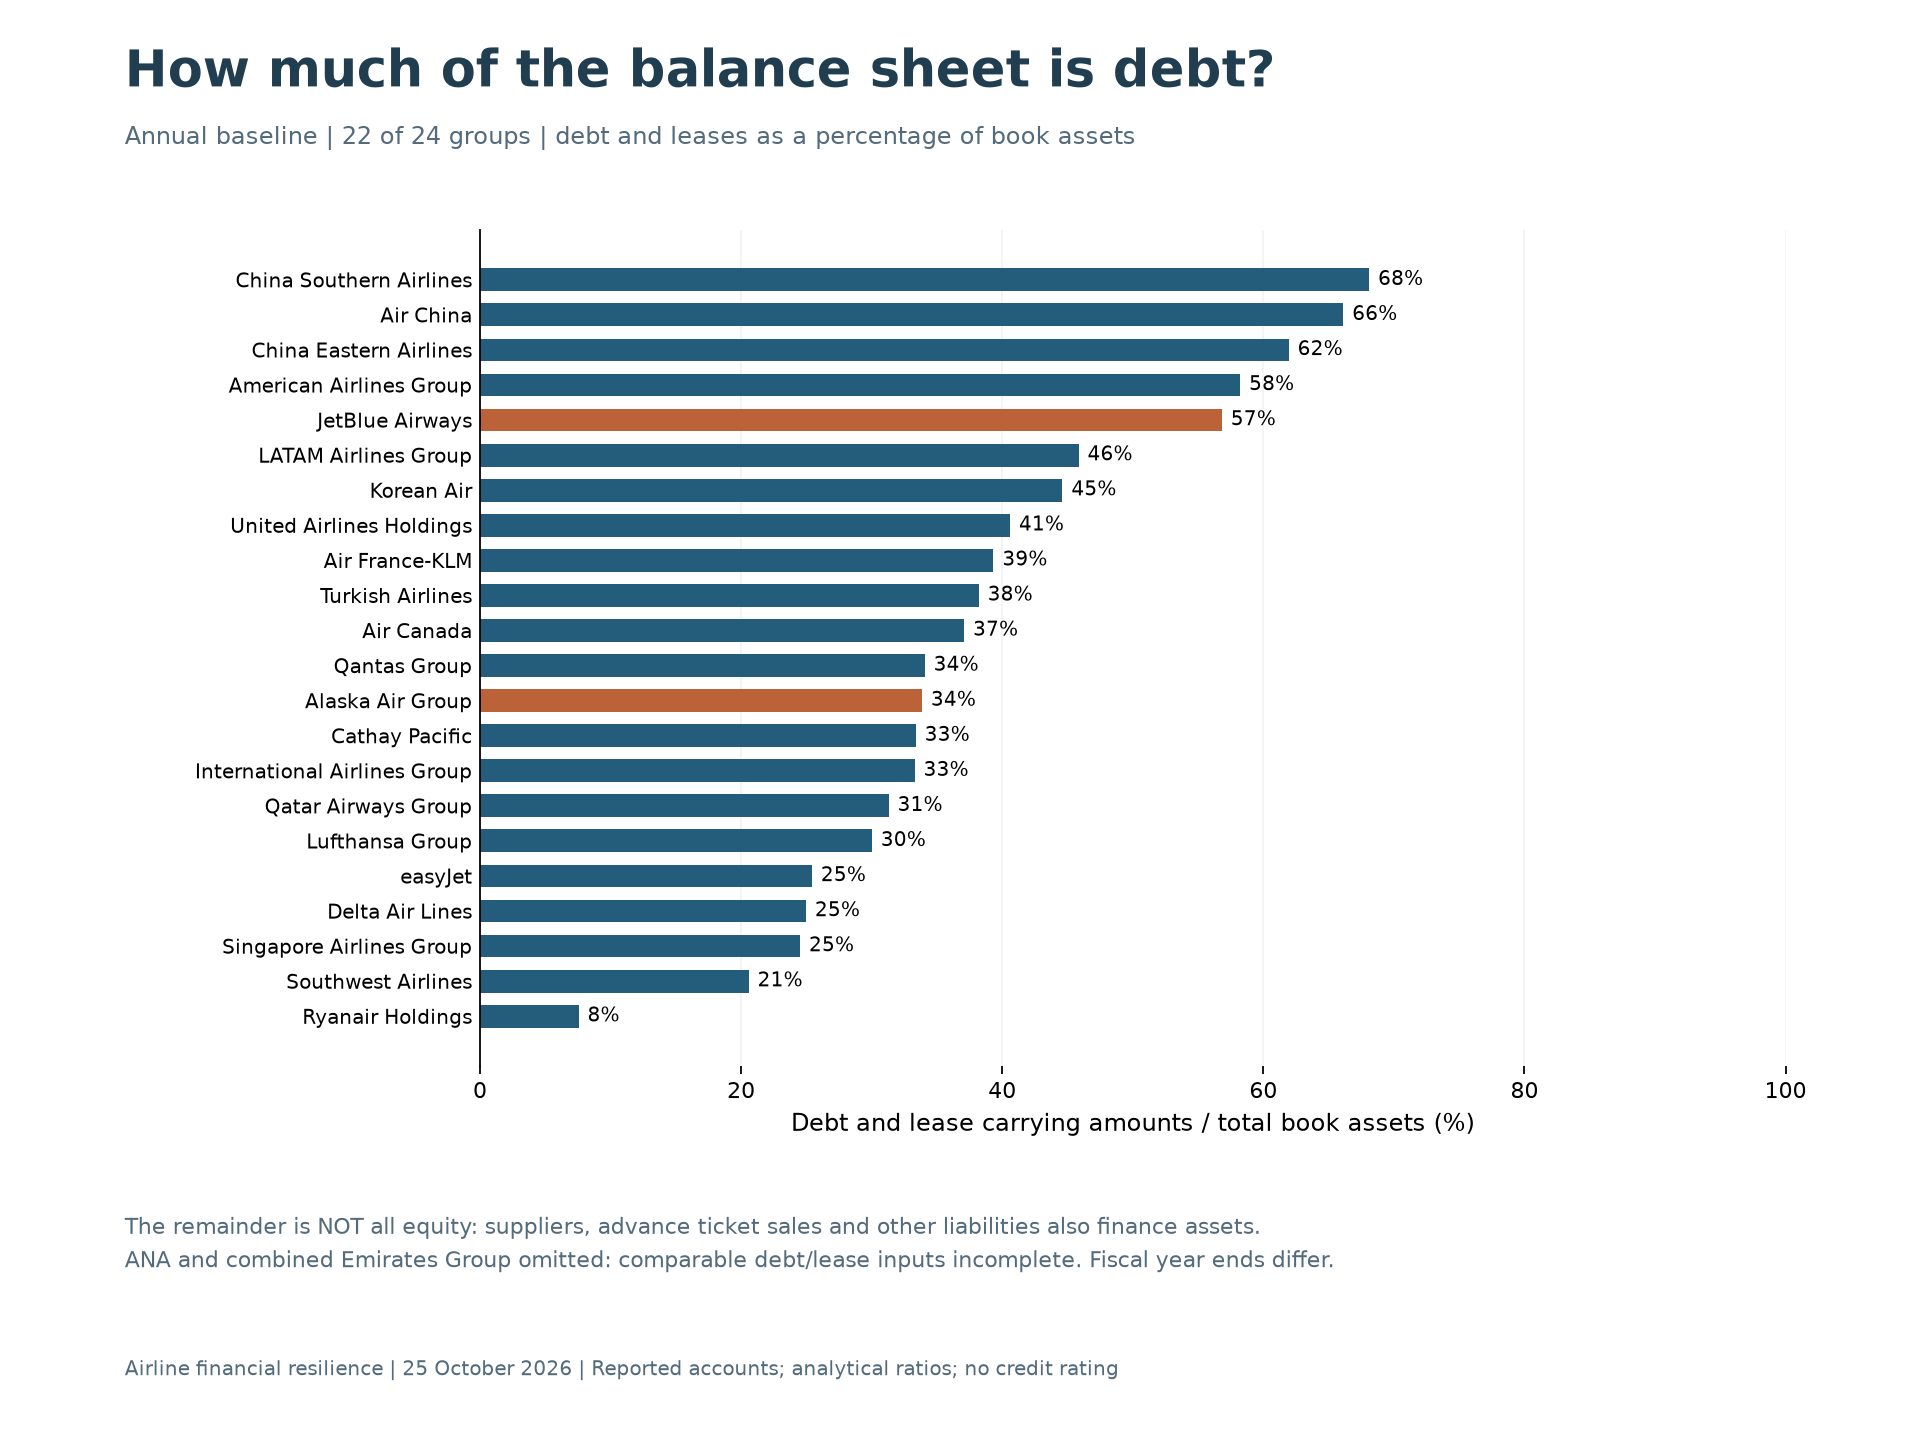

In [2]:
display(case[["entity","period_end","currency","debt_and_lease_carrying_amount","equity","debt_to_equity","debt_to_assets_pct"]].rename(columns={"entity":"Airline","period_end":"Balance sheet date","currency":"Currency","debt_and_lease_carrying_amount":"Debt and leases (m)","equity":"Book equity (m)","debt_to_equity":"Debt / equity (x)","debt_to_assets_pct":"Debt / assets (%)"}).round(2))
display(Image(filename=str(OUT/"balance_sheet_leverage.png")))

## “How much of your earnings goes on interest?”
Interest cover = operating profit / gross interest expense. At 3x cover, interest equals 33% of operating profit. This does not mean 33% of cash is ring-fenced for creditors. If there is an operating loss, no positive earnings percentage is meaningful.

The case comparison uses trailing twelve-month flows ending at the stated dates. The sector figure uses the separate annual baseline. US GAAP and IFRS lease-expense differences remain a comparison limitation.

,Airline,TTM end,Currency,Operating profit / loss (m),Gross interest expense (m),Interest cover (x),Interpretation
0,JetBlue Airways,2026-06-30,USD,-565.00,584.0,-0.97,Operating loss: interest is not covered by ope...
1,Alaska Air Group,2026-09-30,USD,-290.00,329.0,-0.88,Operating loss: interest is not covered by ope...
2,LATAM Airlines Group,2026-06-30,USD,2375.31,NaN,NaN,Gross interest not extracted; coverage unavail...
3,easyJet,2026-03-31,GBP,539.00,NaN,NaN,Gross interest not extracted; coverage unavail...


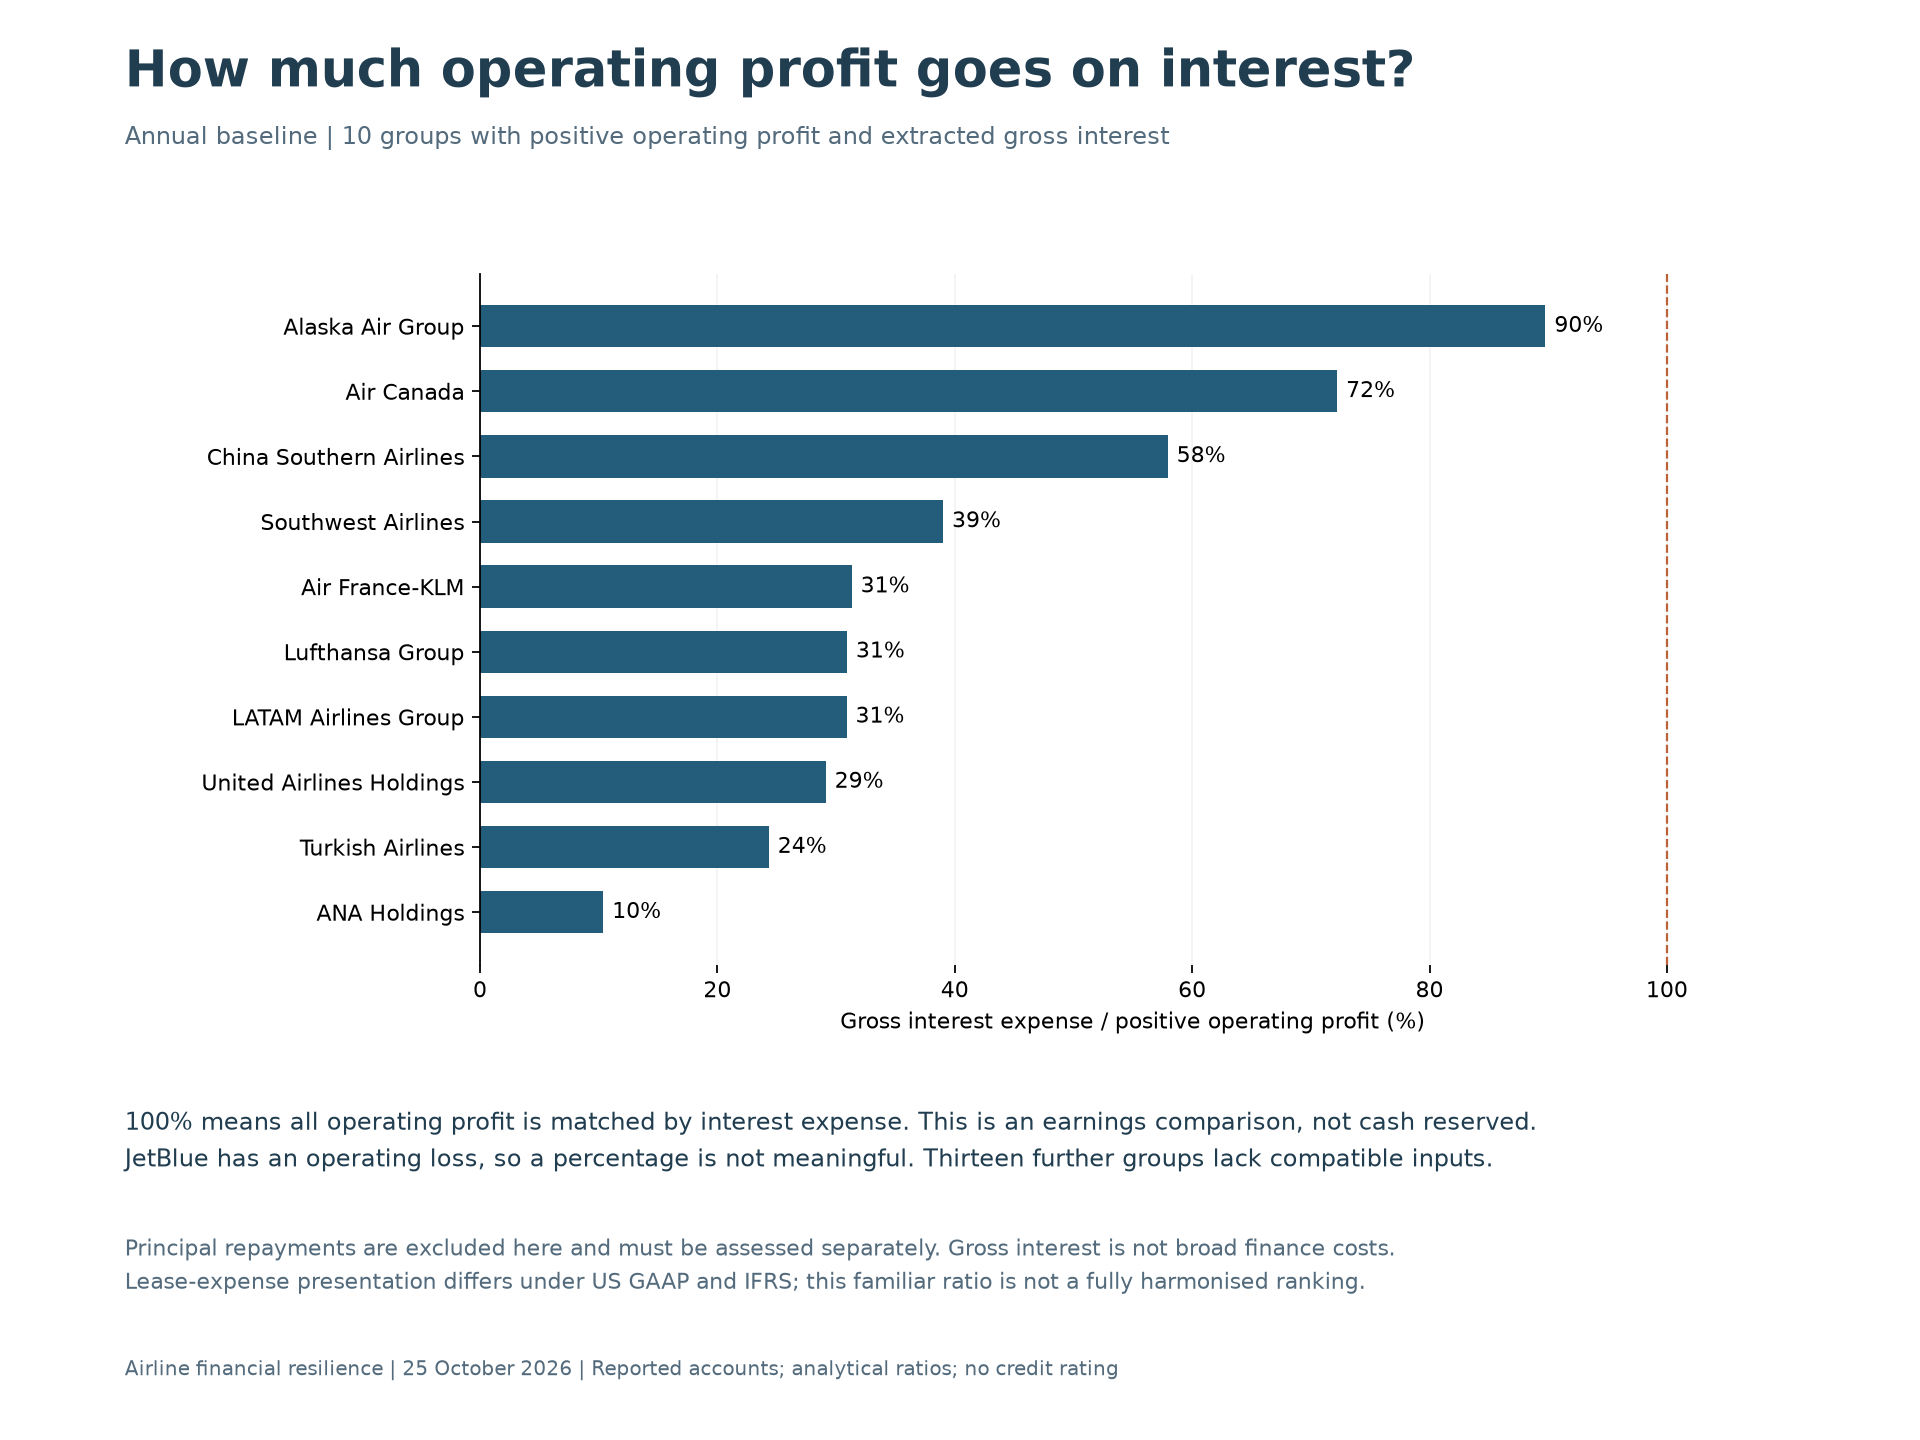

In [3]:
display(case[["entity","period_end","currency","ttm_operating_profit","ttm_interest_expense","interest_cover","interest_reading"]].rename(columns={"entity":"Airline","period_end":"TTM end","currency":"Currency","ttm_operating_profit":"Operating profit / loss (m)","ttm_interest_expense":"Gross interest expense (m)","interest_cover":"Interest cover (x)","interest_reading":"Interpretation"}).round(2))
display(Image(filename=str(OUT/"interest_burden.png")))

## “Can you meet the actual cash repayments?”
Principal repayments matter as well as interest. Use a cash-flow bridge with the same period as the scheduled payments, distinguish necessary capital spending, and avoid subtracting interest or leases twice.

For JetBlue, the June schedule shows **$1,189m of debt and lease payments in calendar 2027**. Aircraft and other commitments are separate. We cannot yet establish what proportion is covered by available cash. The schedule is not a next-twelve-month forecast from October, and its figures can change.

,Payment period,Schedule date,Currency,Debt / finance leases incl. interest,Operating leases,Debt + lease cash commitments,Aircraft purchases,Other commitments,Total listed commitments
0,remainder_2026,2026-06-30,USD,529,81,610,337,211,1158
1,2027,2026-06-30,USD,1043,146,1189,383,397,1969


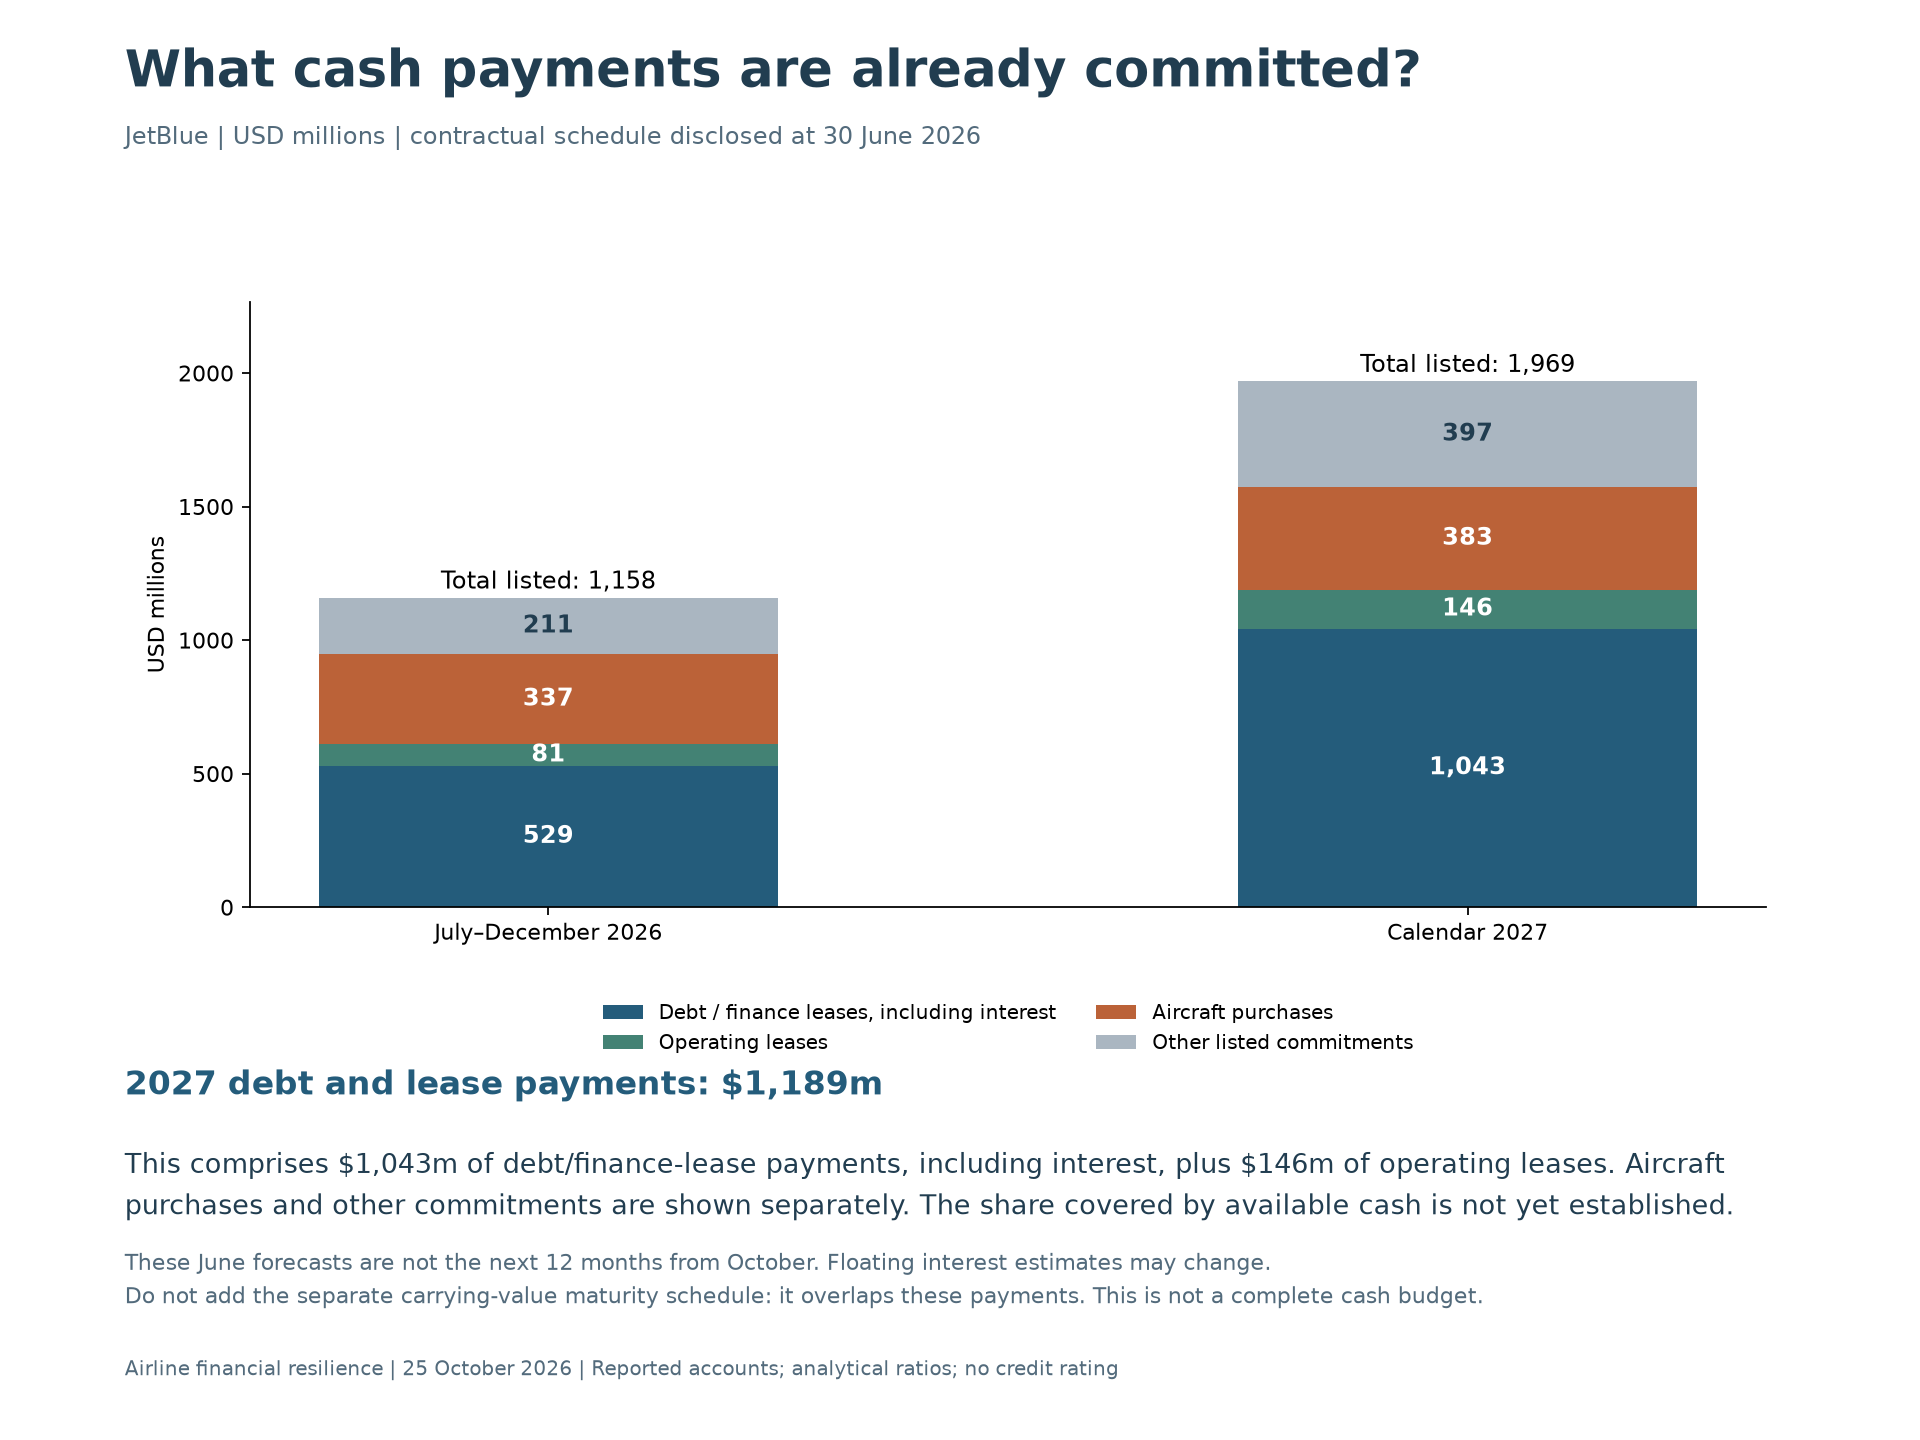

In [4]:
display(jetblue_commitments().drop(columns=["source_url","source_locator"]).rename(columns={"period":"Payment period","as_of":"Schedule date","currency":"Currency","debt_and_finance_lease_payments_including_interest":"Debt / finance leases incl. interest","operating_lease_payments":"Operating leases","debt_and_lease_cash_commitments":"Debt + lease cash commitments","aircraft_purchase_commitments":"Aircraft purchases","other_contractual_commitments":"Other commitments","total_listed_commitments":"Total listed commitments"}))
display(Image(filename=str(OUT/"cash_commitments.png")))

## “Therefore, what is the risk profile?”
The conclusions below are qualitative interpretations of observed evidence—not agency ratings, default probabilities or an investment recommendation. A positive cash-flow period does not prove low risk. Missing evidence does not prove high risk.

Before an overall rating, we need available liquidity, current repayment schedules, covenant headroom, collateral, fuel/FX exposure and a downside cash forecast.

,Airline,Statement date,Observed pressure,Investor discussion
0,JetBlue Airways,2026-06-30,Significant funding pressure,"Operating losses, negative operating cash flow..."
1,Alaska Air Group,2026-09-30,Earnings and funding pressure,"Lower book leverage than JetBlue, but trailing..."
2,LATAM Airlines Group,2026-06-30,Cash generation positive; financing review inc...,June operating cash flow exceeded capital spen...
3,easyJet,2026-03-31,Lower book leverage; seasonal and transaction ...,"Debt and leases are below book equity, and tra..."


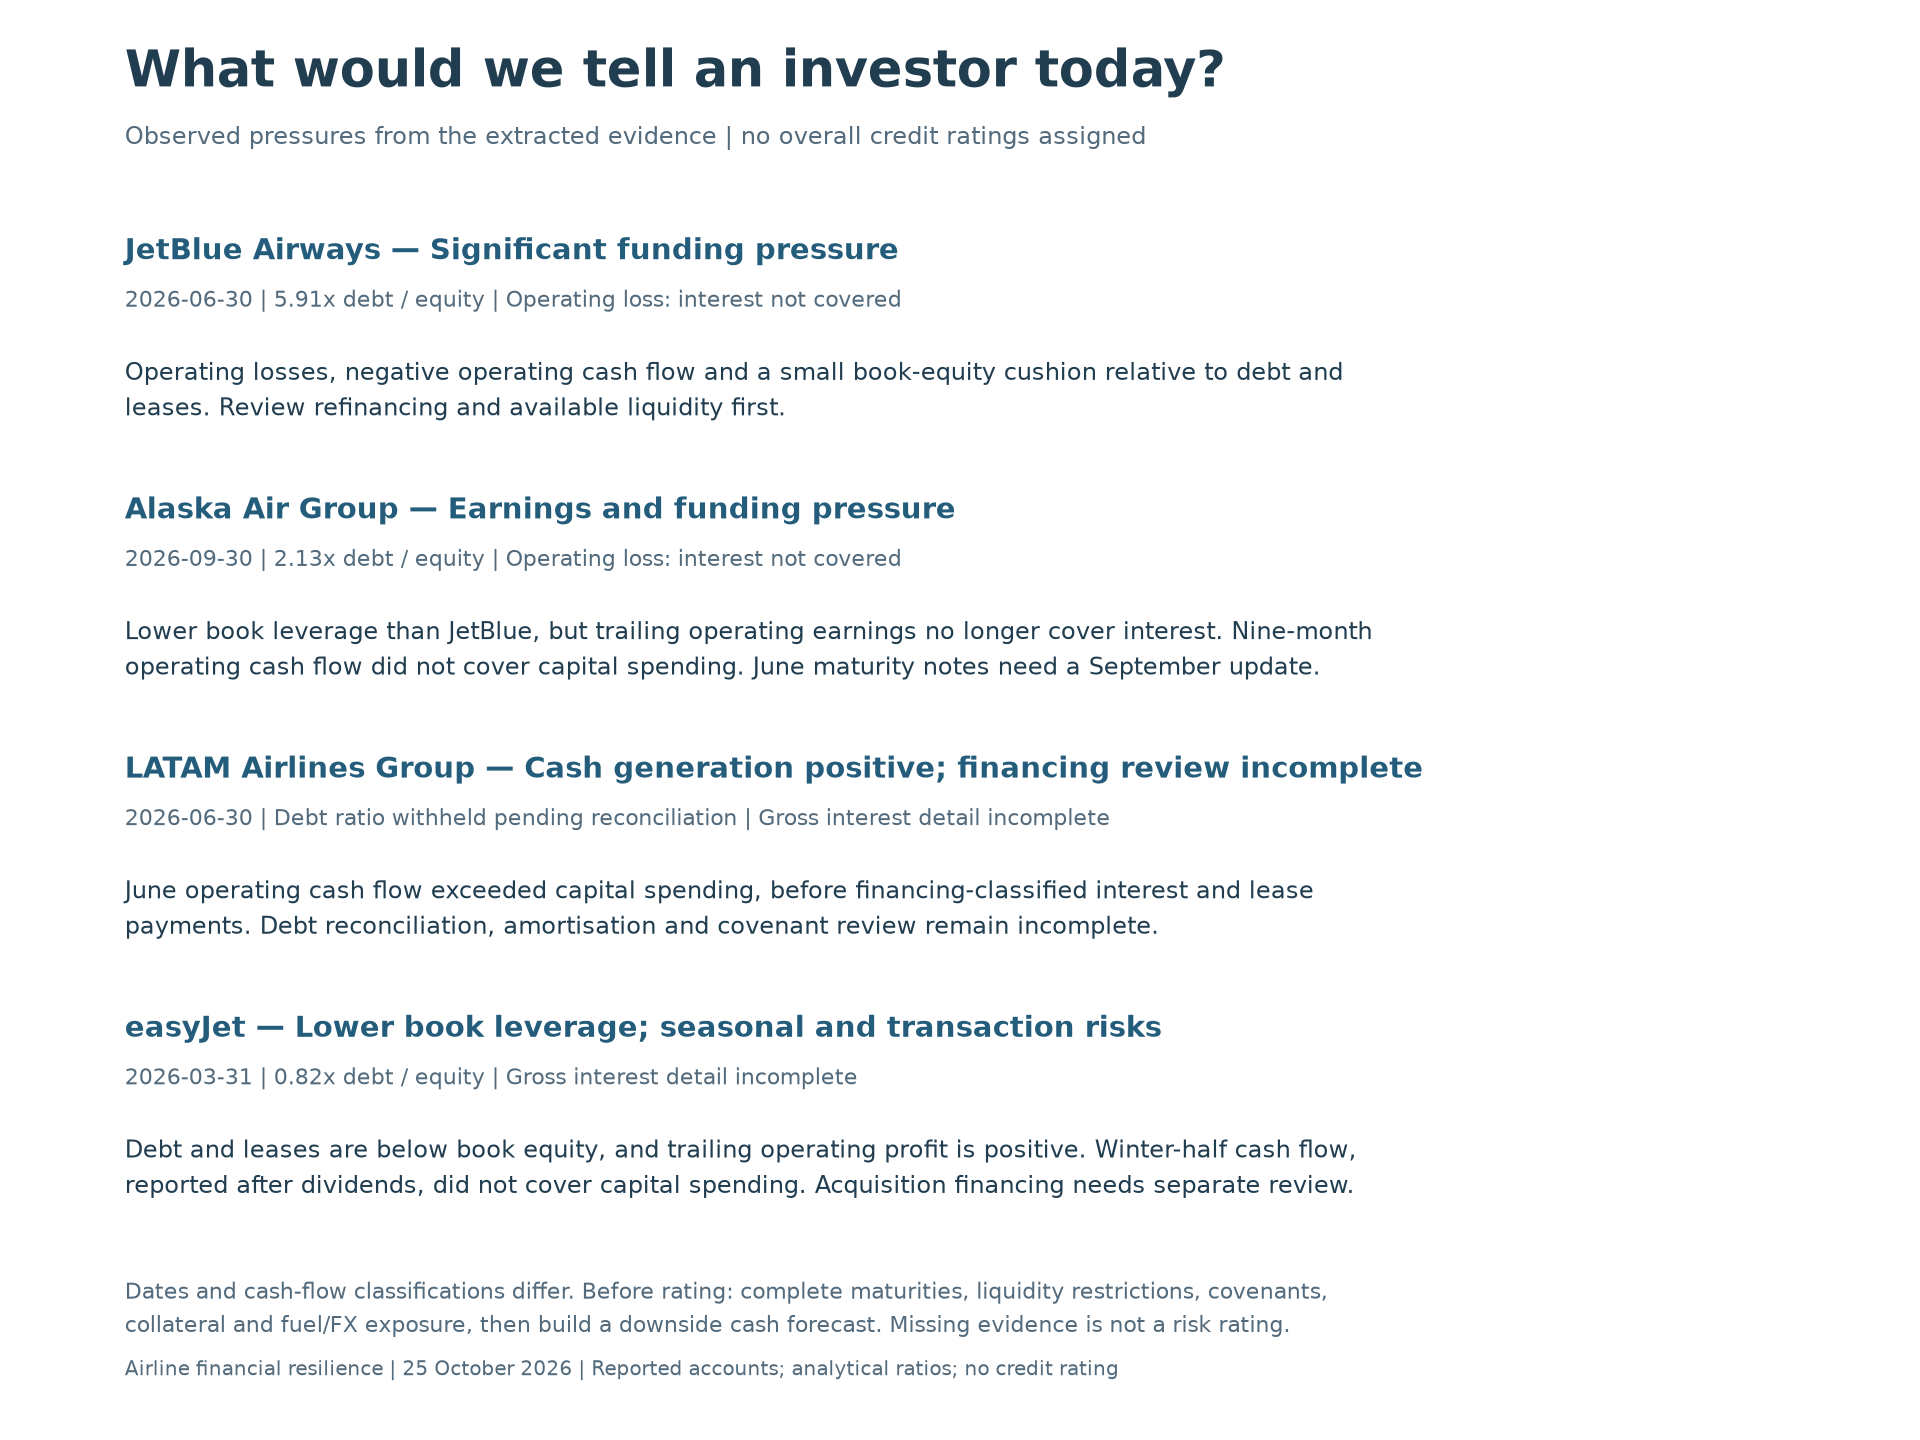

In [5]:
display(case[["entity","period_end","observed_profile","interpretation"]].rename(columns={"entity":"Airline","period_end":"Statement date","observed_profile":"Observed pressure","interpretation":"Investor discussion"}))
display(Image(filename=str(OUT/"risk_discussion.png")))

## Sources and accounting notes
Annual and interim source links and page locators are retained in the database. The cash schedule is JetBlue's June Form10-Q, contractual obligations page36. See [investor guide](../docs/investor-guide.md) and [current evidence guide](../docs/current-evidence.md) for reconciliation limits and the work queue.

The SEC's [non-GAAP guidance](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures) explains why EBITDA and cash-flow substitutes need care. The IFRS Foundation's [lease effects analysis](https://www.ifrs.org/-/media/project/leases/ifrs/published-documents/ifrs16-effects-analysis.pdf) explains differences in expense presentation. No company is labelled “GAAP-comparable” merely because its ratios can be calculated.